## Mount Google Drive

Run the following cell to mount your Google Drive and allow access to your files. If it's a shared drive, its contents will usually be found under `/content/drive/MyDrive/Shared with me/`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Define the shared drive path (Replace <YOUR_SHARED_DRIVE_NAME> with the exact name)
shared_drive_path = '/content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw'

# Change directory
%cd {shared_drive_path}

# List files to verify you are in the correct place
os.listdir()

/content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw


['train', 'valid', 'test', 'augmented_train_5x']

In [ ]:
import os

# Input paths (Images: .jpg, Masks: .png)
# Based on your description, they are directly inside the train folder
input_image_dir = os.path.join(shared_drive_path, 'train')
input_label_dir = os.path.join(shared_drive_path, 'train')

# Define extensions to distinguish between types
IMAGE_EXT = '.jpg'
MASK_EXT = '.png'

# New output directory in RE7_PNG_masks_raw
output_base_dir = os.path.join(shared_drive_path, 'augmented_train_10x')

output_image_dir = os.path.join(output_base_dir, 'images')
output_label_dir = os.path.join(output_base_dir, 'masks')

os.makedirs(output_image_dir, exist_ok=True)
os.makedirs(output_label_dir, exist_ok=True)

print(f"Input directory (Images/Masks): {input_image_dir}")
print(f"Target Extensions: Images ({IMAGE_EXT}), Masks ({MASK_EXT})")
print(f"Output image directory: {output_image_dir}")
print(f"Output mask directory: {output_label_dir}")

Input directory (Images/Masks): /content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw/train
Target Extensions: Images (.jpg), Masks (.png)
Output image directory: /content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw/augmented_train_10x/images
Output mask directory: /content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw/augmented_train_10x/masks


### Install Albumentations

First, we need to install the `albumentations` library, which provides a wide range of image augmentation transforms.

In [ ]:
!pip install -q albumentations opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.5/121.5 kB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.4/369.4 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 583.5/583.5 kB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 103.5 MB/s eta 0:00:00


### Define Augmentation Pipeline

Now, let's define the augmentation pipeline using `albumentations.Compose`. Each transformation will be applied with a 50% probability (`p=0.5`), as is common practice. You can adjust these probabilities or limits as needed.

*   **Horizontal Flip**: Flips the image horizontally.
*   **Rotation**: Rotates the image by a random angle between -15 and +15 degrees.
*   **Random Brightness Contrast**: Adjusts the brightness by ±25%.
*   **Gaussian Blur**: Applies a Gaussian blur with a kernel size of 3x3.
*   **Random Gamma**: Adjusts the image's gamma value between 0.6 and 1.8.

In [ ]:
import albumentations as A
import cv2
import numpy as np

define_transforms = A.Compose([
    A.HorizontalFlip(p=0.5), # Horizontal Flip
    A.Rotate(limit=15, p=0.15), # Rotation limit set to ±15°
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0, p=0.15), # Brightness limit set to ±25%
    A.GaussianBlur(blur_limit=(3, 3), p=0.05), # Gaussian Blur with 3x3 kernel limit
    A.RandomGamma(gamma_limit=(60, 180), p=0.15) # Gamma range set to 0.6 – 1.8 (Albumentations uses 100*gamma)
],
bbox_params=None, # Explicitly state no bounding box params
keypoint_params=None # Explicitly state no keypoint params
)

print("Augmentation pipeline defined successfully for image and masks!")

Augmentation pipeline defined successfully for image and masks!


In [ ]:
import os
import cv2
import numpy as np

# Helper function to load semantic segmentation masks
def load_mask(mask_path):
    # Load mask as grayscale
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return None
    return mask

print("Semantic segmentation utility functions defined.")

Semantic segmentation utility functions defined.


### Augmenting Images and YOLO Labels

This code block demonstrates how to apply the `define_transforms` to an image and its YOLO annotations, and then save the augmented results. You'll need to specify the paths to your original image and label, and where you want to save the augmented versions.

**Key steps:**
1.  **Load Image and Labels**: Reads an image and its corresponding YOLO label file.
2.  **Parse YOLO Labels**: Converts YOLO format (normalized `xc yc w h class_id`) into a format `albumentations` understands.
3.  **Apply Augmentations**: Uses `define_transforms` to augment both the image and the bounding boxes.
4.  **Save Augmented Data**: Writes the augmented image and the new YOLO label file.

### Augmenting Images and YOLO Labels

This code block demonstrates how to apply the `define_transforms` to an image and its YOLO annotations, and then save the augmented results. You'll need to specify the paths to your original image and label, and where you want to save the augmented versions.

**Key steps:**
1.  **Load Image and Labels**: Reads an image and its corresponding YOLO label file.
2.  **Parse YOLO Labels**: Converts YOLO format (normalized `xc yc w h class_id`) into a format `albumentations` understands.
3.  **Apply Augmentations**: Uses `define_transforms` to augment both the image and the bounding boxes.
4.  **Save Augmented Data**: Writes the augmented image and the new YOLO label file.

Starting test augmentation for: A2_jpg.rf.5ed686d7376c7a8b2c35f4348d38b298.jpg


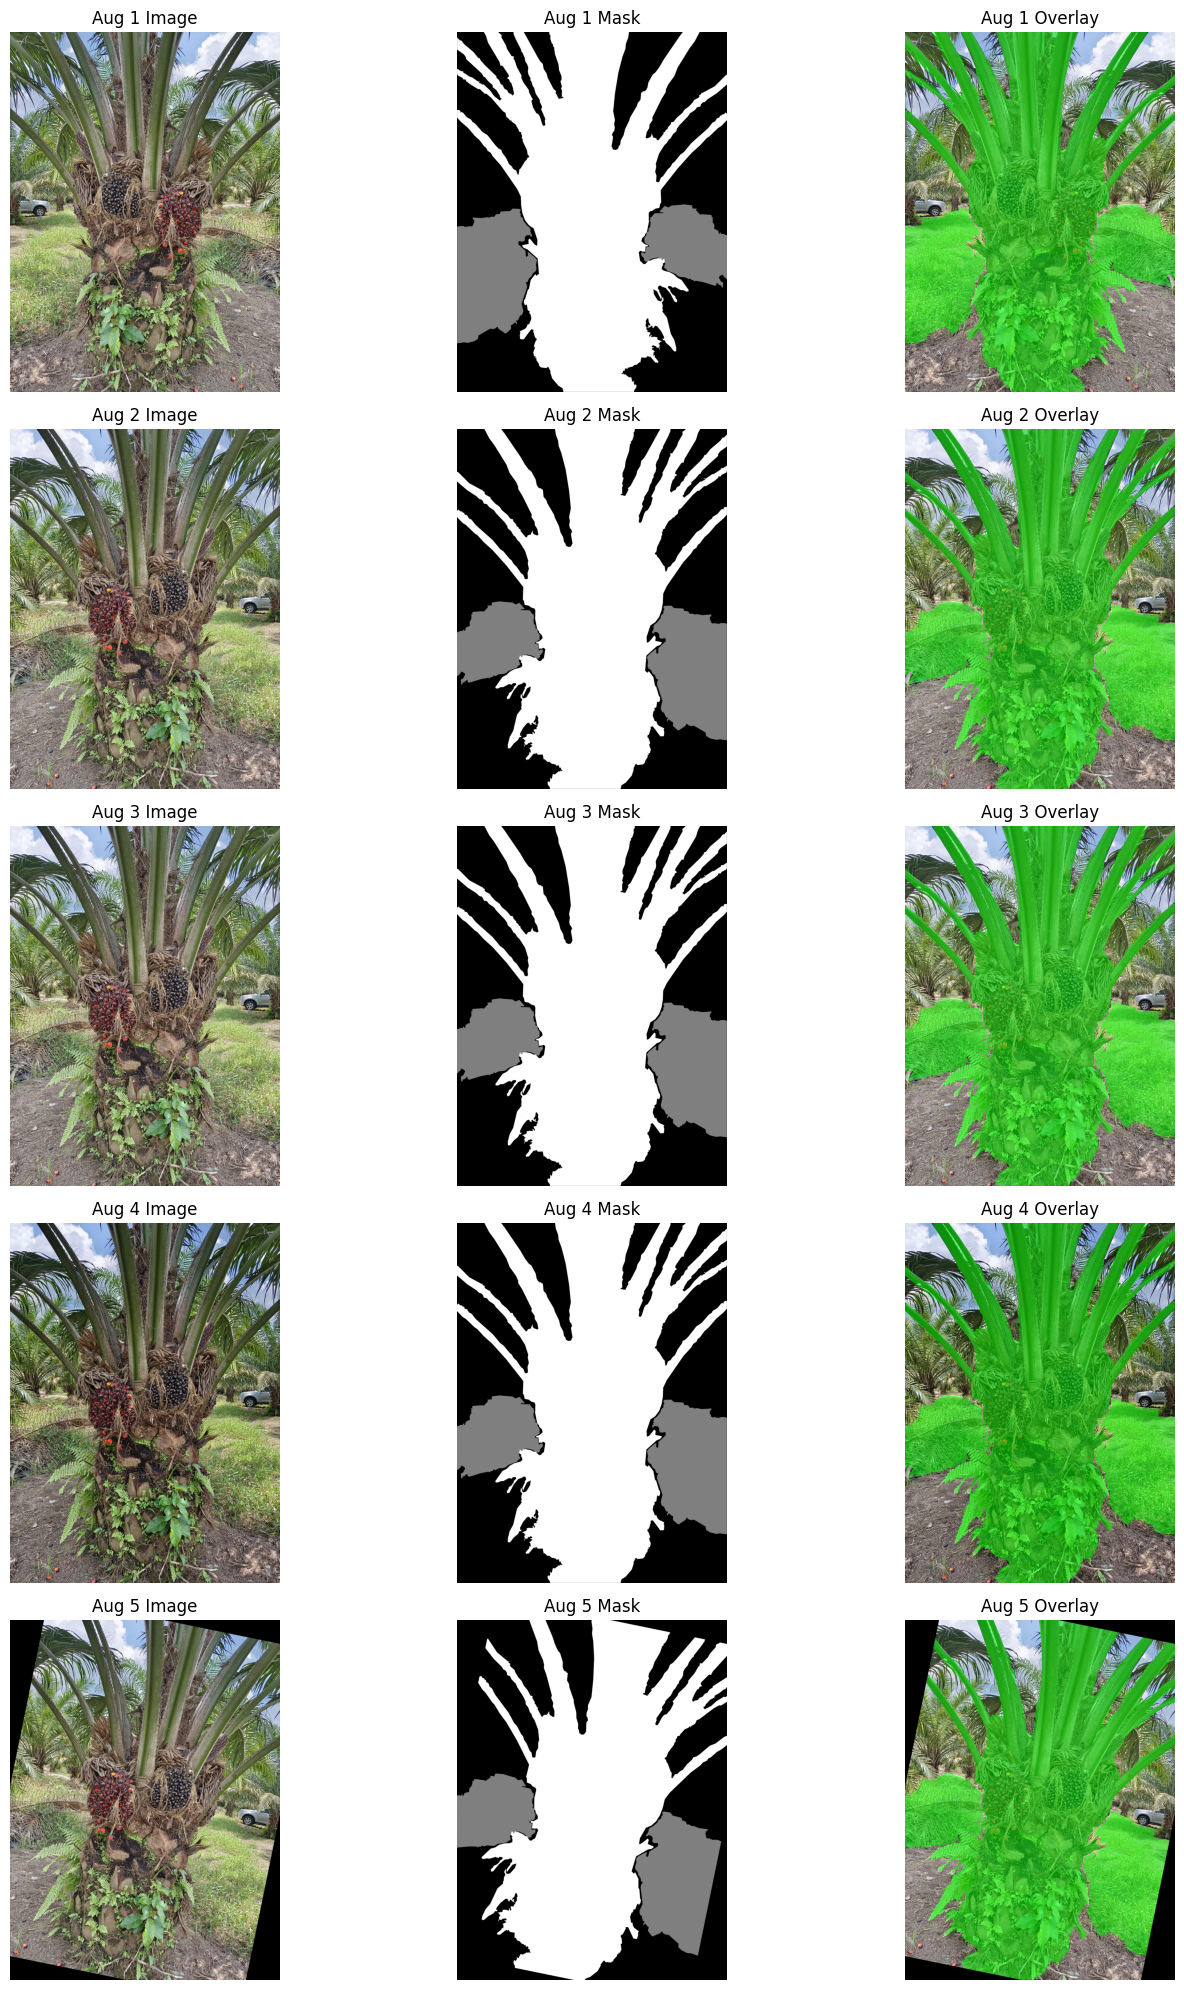

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Test Configuration for single pair ---
test_image_name = 'A2_jpg.rf.5ed686d7376c7a8b2c35f4348d38b298.jpg'
test_mask_name = 'A2_jpg.rf.5ed686d7376c7a8b2c35f4348d38b298_mask.png'

test_img_path = os.path.join(input_image_dir, test_image_name)
test_mask_path = os.path.join(input_label_dir, test_mask_name)

# Load
img = cv2.imread(test_img_path)
mask = cv2.imread(test_mask_path, cv2.IMREAD_GRAYSCALE)

if img is None or mask is None:
    print(f"Error: Check filenames. Image found: {img is not None}, Mask found: {mask is not None}")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    print(f"Starting test augmentation for: {test_image_name}")

    fig, axes = plt.subplots(5, 3, figsize=(15, 20))

    for i in range(5):
        # Transform
        transformed = define_transforms(image=img, mask=mask)
        aug_img = transformed['image']
        aug_mask = transformed['mask']

        # Create overlay (green tint for mask)
        overlay = aug_img.copy()
        overlay[aug_mask > 0] = overlay[aug_mask > 0] * 0.5 + np.array([0, 255, 0], dtype=np.uint8) * 0.5

        # Visualize
        axes[i, 0].imshow(aug_img)
        axes[i, 0].set_title(f"Aug {i+1} Image")
        axes[i, 1].imshow(aug_mask, cmap='gray')
        axes[i, 1].set_title(f"Aug {i+1} Mask")
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title(f"Aug {i+1} Overlay")

        for ax in axes[i]: ax.axis('off')

    plt.tight_layout()
    plt.show()

# --- Original loop remains below ---
# [Rest of your original code follows...]

# Get list of all image files (.jpg)
# image_files = [f for f in os.listdir(input_image_dir) if f.lower().endswith('.jpg')]
# ... (and so on)


In [ ]:
import os
import cv2
import numpy as np

# --- Configuration for your dataset ---
# The directories were already defined in the previous cells
# Images are .jpg, Masks are _mask.png

# Number of augmentations to generate per original image
num_augmentations_per_image = 10
# -------------------------------------- #

# Get list of all image files (.jpg)
image_files = [f for f in os.listdir(input_image_dir) if f.lower().endswith('.jpg')]

print(f"Found {len(image_files)} images in '{input_image_dir}'. Starting augmentation...")

for image_filename in image_files:
    input_image_path = os.path.join(input_image_dir, image_filename)
    # The corresponding mask file ends with _mask.png
    base_filename = os.path.splitext(image_filename)[0]
    input_mask_path = os.path.join(input_label_dir, base_filename + '_mask.png')

    # Load original image
    original_image = cv2.imread(input_image_path)
    if original_image is None:
        print(f"Error: Could not load image from {input_image_path}. Skipping.")
        continue

    original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

    # Load original mask
    original_mask = cv2.imread(input_mask_path, cv2.IMREAD_GRAYSCALE)
    if original_mask is None:
        print(f"Warning: Mask file {input_mask_path} not found. Skipping {image_filename}.")
        continue

    # Generate multiple augmented versions
    for i in range(num_augmentations_per_image):
        try:
            # Apply transformations to both image and mask
            transformed = define_transforms(image=original_image, mask=original_mask)
            augmented_image = transformed['image']
            augmented_mask = transformed['mask']

            # Define output paths
            current_output_image_path = os.path.join(output_image_dir, f"aug_{i}_{image_filename}")
            # Keeping the _mask suffix in output for consistency
            current_output_mask_path = os.path.join(output_label_dir, f"aug_{i}_{base_filename}_mask.png")

            # Save augmented image (convert back to BGR for cv2)
            cv2.imwrite(current_output_image_path, cv2.cvtColor(augmented_image, cv2.COLOR_RGB2BGR))

            # Save augmented mask
            cv2.imwrite(current_output_mask_path, augmented_mask)

            if (i+1) == num_augmentations_per_image:
                print(f"Finished {num_augmentations_per_image} augmentations for {image_filename}")

        except Exception as e:
            print(f"Error during augmentation {i} for {image_filename}: {e}")

print(f"\nAugmentation complete! Results saved in '{output_image_dir}' and '{output_label_dir}'.")

Found 242 images in '/content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw/train'. Starting augmentation...
Finished 10 augmentations for A11_jpg.rf.c1c1d32f21c532e100ea638844e87a91.jpg
Finished 10 augmentations for A13_jpg.rf.44262d7f93fa8ddd8b01669e9f6d3fbe.jpg
Finished 10 augmentations for A15_jpg.rf.93295a2dcb371a632aa6ee50a3948b32.jpg
Finished 10 augmentations for A18_jpg.rf.cad8e333f8fed2e1a083a0ac8a1a4e3b.jpg
Finished 10 augmentations for A14_jpg.rf.80737bfc0387a3ac5c3c5d5d3c5bd1b8.jpg
Finished 10 augmentations for A16_jpg.rf.372094d1b1f3b742c8b9963beacde2b2.jpg
Finished 10 augmentations for A25_jpg.rf.48707a8c7abd9c133c7a3a2fce79b1f8.jpg
Finished 10 augmentations for A23_jpg.rf.4892db6b7164fa34e470bf5bc895cb12.jpg
Finished 10 augmentations for A2_jpg.rf.5ed686d7376c7a8b2c35f4348d38b298.jpg
Finished 10 augmentations for A24_jpg.rf.9fb077754cc8d5f94648711c2a34d122.jpg
Finished 10 augmentations for A22_jpg.rf.2

## Calculate Frechet Inception Distance (FID) Score

As per your request, we will now calculate the FID score. This metric quantifies the similarity between two sets of images. In this case, we will compare the **original dataset** with the **augmented dataset**.

A lower FID score indicates that the distributions of the two image sets (original and augmented) are more similar in the feature space of the InceptionV3 model. While not its primary use, this can provide an insight into how 'different' your augmented images are from the originals after the transformations.

In [ ]:
# Install TensorFlow if not already installed (usually present in Colab)
try:
    import tensorflow as tf
except ImportError:
    !pip install -q tensorflow
    import tensorflow as tf

import numpy as np
from scipy.linalg import sqrtm
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import os

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 779.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 115.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 73.3 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [ ]:
def scale_images(images, new_shape):
    images_list = list()
    for image in images:
        # resize image to new_shape
        image = tf.image.resize(image, new_shape)
        # store
        images_list.append(image)
    return np.asarray(images_list)

# Function to load and preprocess images for InceptionV3, creating overlays for pairs
def load_images_from_directory(directory, img_size=(299, 299), is_augmented=False):
    images = []

    if not is_augmented:
        # Original: images and masks are in the same 'train' folder
        files = [f for f in os.listdir(directory) if f.lower().endswith('.jpg')]
        for filename in files:
            base = os.path.splitext(filename)[0]
            img_path = os.path.join(directory, filename)
            mask_path = os.path.join(directory, base + '_mask.png')

            if os.path.exists(mask_path):
                img = cv2.imread(img_path)
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                if img is not None and mask is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    overlay = img.copy()
                    overlay[mask > 0] = overlay[mask > 0] * 0.5 + np.array([0, 255, 0], dtype=np.uint8) * 0.5
                    overlay = cv2.resize(overlay, img_size)
                    images.append(overlay)
    else:
        # Augmented: images are in 'images' folder, masks in 'masks' folder
        aug_img_dir = os.path.join(directory, 'images')
        aug_mask_dir = os.path.join(directory, 'masks')

        files = [f for f in os.listdir(aug_img_dir) if f.lower().endswith('.jpg')]
        for filename in files:
            img_path = os.path.join(aug_img_dir, filename)
            # Suffix remains _mask.png in the masks folder
            base = os.path.splitext(filename)[0]
            mask_path = os.path.join(aug_mask_dir, base + '_mask.png')

            if os.path.exists(mask_path):
                img = cv2.imread(img_path)
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                if img is not None and mask is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    overlay = img.copy()
                    overlay[mask > 0] = overlay[mask > 0] * 0.5 + np.array([0, 255, 0], dtype=np.uint8) * 0.5
                    overlay = cv2.resize(overlay, img_size)
                    images.append(overlay)

    images = np.array(images)
    if len(images) > 0:
        images = preprocess_input(images.astype('float32'))
    return images

# Function to calculate FID
def calculate_fid(act1, act2):
    mu1, sigma1 = act1.mean(axis=0), np.cov(act1, rowvar=False)
    mu2, sigma2 = act2.mean(axis=0), np.cov(act2, rowvar=False)
    ssdiff = np.sum((mu1 - mu2)**2.0)
    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    fid = ssdiff + np.trace(sigma1 + sigma2 - 2.0 * covmean)
    return fid

In [ ]:
print("Loading InceptionV3 model...")
model = InceptionV3(include_top=False, pooling='avg', input_shape=(299, 299, 3))
print("InceptionV3 model loaded.")

# Define paths
original_images_dir = input_image_dir
augmented_root_dir = output_base_dir

print(f"Loading original overlays from: {original_images_dir}")
images_original = load_images_from_directory(original_images_dir, is_augmented=False)
print(f"Loaded {len(images_original)} original overlay images.")

print(f"Loading augmented overlays from folders inside: {augmented_root_dir}")
images_augmented = load_images_from_directory(augmented_root_dir, is_augmented=True)
print(f"Loaded {len(images_augmented)} augmented overlay images.")

if len(images_original) == 0 or len(images_augmented) == 0:
    print("Error: Not enough images loaded to calculate FID.")
else:
    print("Extracting features from original overlays...")
    features_original = model.predict(images_original)

    print("Extracting features from augmented overlays...")
    features_augmented = model.predict(images_augmented)

    print("Calculating FID score...")
    fid_score = calculate_fid(features_original, features_augmented)
    print(f"\nFID score between original overlays and augmented overlays: {fid_score:.4f}")

Loading InceptionV3 model...
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
InceptionV3 model loaded.
Loading original overlays from: /content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw/train
Loaded 242 original overlay images.
Loading augmented overlays from folders inside: /content/drive/.shortcut-targets-by-id/1GAp31sUzRLUjs7X2S65MjpEaDOxrpRLU/Capstone_NFW_workspace/Datasets_2/RE7_PNG_masks_raw/augmented_train_10x
Loaded 2420 augmented overlay images.
Extracting features from original overlays...
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step
Extracting features from augmented overlays...
76/76 ━━━━━━━━━━━━━━━━━━━━ 200s 3s/step
Calculating FID score...

FID score between original overlays and augmented overlays: 15.8056
